# **Laboratorio** # **4 — Minería de Datos**
**Integrantes del grupo:**
- López Rodríguez Lucas
- Murillo Cruz Sheyla Daliana
- Oporta Rosales Mauricio
- Sancho Ruiz Justin


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

###  **Carga de los conjuntos de datos desde Git en Google Colab** #

In [3]:
url_repo = "https://raw.githubusercontent.com/sheylamurillo/laboratorio4_conjunto-de-datos/main/"
url_lfs = "https://media.githubusercontent.com/media/sheylamurillo/laboratorio4_conjunto-de-datos/main/"

def cargar_csv(archivo, usa_lfs=False, nrows=None):
    url = (url_lfs if usa_lfs else url_repo) + archivo
    df = pd.read_csv(url, nrows=nrows)
    return df

df_movies = cargar_csv("movies.csv", usa_lfs=False)
df_ratings = cargar_csv("ratings.csv", usa_lfs=True, nrows=500000)

###  **Visualizar características básicas** #
* **movies.csv:** Cuenta con **62,423 filas** y **3 columnas** (movieId en int64, y title y genres en object). Presenta **62,325** títulos únicos (con The Forest (2016) repitiéndose 2 veces) y **1,639** combinaciones de géneros únicas, siendo Drama la más frecuente (9,056 registros).
* **ratings.csv:** Evaluado sobre una muestra de **500,000 filas** y **4 columnas** (userId, movieId y timestamp en int64, y rating en float64). La variable rating se encuentra entre **0.5** y **5.0**, con media de **3.55**, mediana de **4.00**.

In [4]:
def explorar(df, nombre):

    print(f"Conjunto de datos: {nombre}")

    # Total de registros de filas y columnas
    print(f"Cantidad de (filas, columnas): {df.shape}\n")

    # Primeros registros para verificar estructura y valores
    print("--- Primeras 5 filas ---")
    display(df.head())

    # Tipos de datos por columna y cantidad de valores no nulos
    print("\n--- Información de columnas y tipos de datos ---")
    df.info()

    # Medidas de tendencia central, dispersión y frecuencias generales
    print("\n--- Medidas de tendencia central, dispersión y frecuencias generales ---")
    display(df.describe(include="all"))


explorar(df_movies, "df_movies (movies.csv)")
explorar(df_ratings, "df_ratings (ratings.csv)")

Conjunto de datos: df_movies (movies.csv)
Cantidad de (filas, columnas): (62423, 3)

--- Primeras 5 filas ---


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy



--- Información de columnas y tipos de datos ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62423 entries, 0 to 62422
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  62423 non-null  int64 
 1   title    62423 non-null  object
 2   genres   62423 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.4+ MB

--- Medidas de tendencia central, dispersión y frecuencias generales ---


,movieId,title,genres
count,62423.000000,62423,62423
unique,NaN,62325,1639
top,NaN,The Forest (2016),Drama
freq,NaN,2,9056
mean,122220.387646,NaN,NaN
std,63264.744844,NaN,NaN
min,1.000000,NaN,NaN
25%,82146.500000,NaN,NaN
50%,138022.000000,NaN,NaN
75%,173222.000000,NaN,NaN


Conjunto de datos: df_ratings (ratings.csv)
Cantidad de (filas, columnas): (500000, 4)

--- Primeras 5 filas ---


,userId,movieId,rating,timestamp
0,1,296,5.0,1147880044
1,1,306,3.5,1147868817
2,1,307,5.0,1147868828
3,1,665,5.0,1147878820
4,1,899,3.5,1147868510



--- Información de columnas y tipos de datos ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     500000 non-null  int64  
 1   movieId    500000 non-null  int64  
 2   rating     500000 non-null  float64
 3   timestamp  500000 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 15.3 MB

--- Medidas de tendencia central, dispersión y frecuencias generales ---


,userId,movieId,rating,timestamp
count,500000.000000,500000.000000,500000.000000,5.000000e+05
mean,1745.358206,20637.567424,3.549066,1.206606e+09
std,976.020643,38556.390766,1.055825,2.295781e+08
min,1.000000,1.000000,0.500000,7.896520e+08
25%,897.000000,1131.000000,3.000000,9.956829e+08
50%,1751.000000,2792.000000,4.000000,1.176779e+09
75%,2580.000000,7934.000000,4.000000,1.444217e+09
max,3445.000000,208939.000000,5.000000,1.574254e+09


### **Cambiar nombres de columnas a español** #

In [5]:
# Columnas de movies a español
df_movies = df_movies.rename(columns={
    "movieId": "id_pelicula",
    "title": "titulo",
    "genres": "generos"
})

# Columnas de ratings a español
df_ratings = df_ratings.rename(columns={
    "userId": "id_usuario",
    "movieId": "id_pelicula",
    "rating": "calificacion",
    "timestamp": "fecha_hora"
})


print("Columnas movies:", df_movies.columns.tolist())
print("Columnas ratings:", df_ratings.columns.tolist())

Columnas movies: ['id_pelicula', 'titulo', 'generos']
Columnas ratings: ['id_usuario', 'id_pelicula', 'calificacion', 'fecha_hora']


###  **Detectar nulos y generar evidencia gráfica** #
Se evaluaron df_movies y df_ratings en busca de valores nulos y cadenas vacías/espacios y se confirmaron **0 valores nulos**  y **0 cadenas vacías** en todas las columnas de ambos conjuntos. La verificación se realizó sobre el total de registros de df_ratings (**25,000,095** datos), manteniendo el mismo resultado de 0 nulos, y para fines gráficos y de practicidad se trabajó con una muestra de **500,000 datos**.

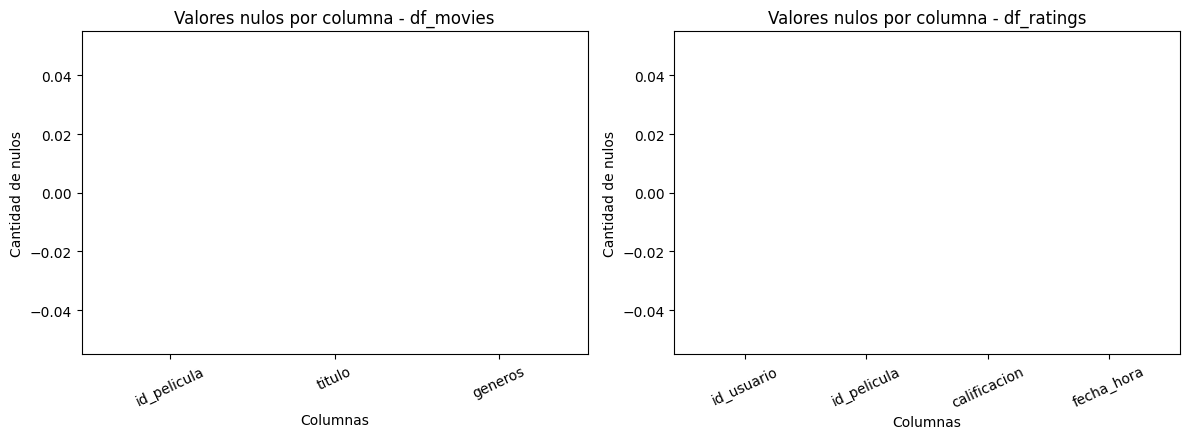

In [6]:
nulos_movies = df_movies.isnull().sum().to_frame(name="valores_nulos")
nulos_ratings = df_ratings.isnull().sum().to_frame(name="valores_nulos")
# --- Grafica de barras
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Gráfico de barras de nulos en df_movies
axes[0].bar(nulos_movies.index, nulos_movies["valores_nulos"], color="skyblue")
axes[0].set_title("Valores nulos por columna - df_movies")
axes[0].set_xlabel("Columnas")
axes[0].set_ylabel("Cantidad de nulos")
axes[0].tick_params(axis="x", rotation=25)

# Gráfico de barras de nulos en df_ratings
axes[1].bar(nulos_ratings.index, nulos_ratings["valores_nulos"], color="skyblue")
axes[1].set_title("Valores nulos por columna - df_ratings")
axes[1].set_xlabel("Columnas")
axes[1].set_ylabel("Cantidad de nulos")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

### **Valores atípicos con evidencia gráfica**

Calculando los cuartiles sobre calificacion se obtuvo **Q1 =** 3.00 y **Q3 =** 4.00 **IQR =** 1.00. Al aplicar la regla de Tukey, los límites resultaron en **1.50** (inferior) y **5.50** (superior), marcando **22,012 registros** por debajo del límite inferior (notas de 0.5 y 1.0) y **0** por encima del superior.

* **Boxplot:** Muestra el grueso central entre 3.0 y 4.0, los límites de 1.50 (rojo) y 5.50 (verde), y los puntos aislados en 0.5 y 1.0.
* **Histograma:** Evidencia mayor concentración entre 3.0 y 5.0 y menor frecuencia en las notas bajas.


Q1 = 3.00 | Q3 = 4.00 | IQR = 1.00
Límites IQR = [1.50, 5.50]
Fuera de rango IQR = 22012


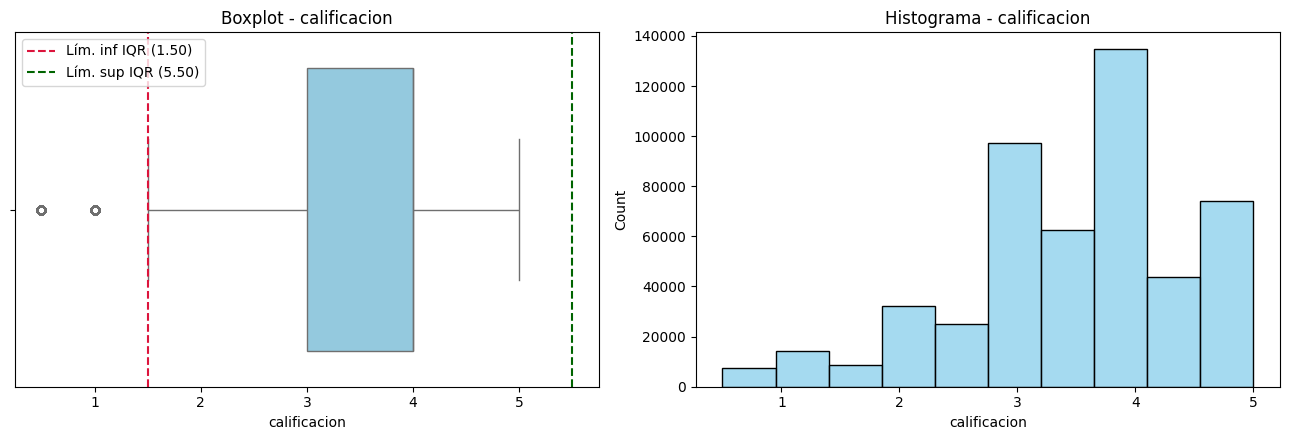

In [7]:
# Variable numérica de df_ratings
col = "calificacion"

# Cálculo del IQR
q1 = df_ratings[col].quantile(0.25)
q3 = df_ratings[col].quantile(0.75)
iqr = q3 - q1
lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr

atipicos_iqr = df_ratings[(df_ratings[col] < lim_inf) | (df_ratings[col] > lim_sup)][col]
print(f"Q1 = {q1:.2f} | Q3 = {q3:.2f} | IQR = {iqr:.2f}")
print(f"Límites IQR = [{lim_inf:.2f}, {lim_sup:.2f}]")
print(f"Fuera de rango IQR = {len(atipicos_iqr)}")

# Boxplot e Histograma
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.boxplot(x=df_ratings[col], ax=axes[0], color="skyblue")
axes[0].axvline(lim_inf, color="crimson", linestyle="--", label=f"Lím. inf IQR ({lim_inf:.2f})")
axes[0].axvline(lim_sup, color="darkgreen", linestyle="--", label=f"Lím. sup IQR ({lim_sup:.2f})")
axes[0].set_title(f"Boxplot - {col}")
axes[0].legend()

sns.histplot(df_ratings[col], bins=10, kde=False, ax=axes[1], color="skyblue")
axes[1].set_title(f"Histograma - {col}")

plt.tight_layout()
plt.show()

### **Tratamiento de datos faltantes y valores atípicos**

* **df_movies:** No presenta nulos en pandas, pero contiene **5,062 películas** con el marcador **(no genres listed)**. Se utiliza una función de imputación para reemplazar esa información faltante por **Sin género informado**, sin atribuir un género supuesto.
* **df_ratings:** No presenta valores nulos en las **500,000 filas analizadas**. Se conservan las **22,012 calificaciones** de 0.5 y 1.0 identificadas como atípicas por IQR, porque pertenecen a la escala válida de MovieLens. Reemplazarlas por la media alteraría las opiniones registradas.


In [8]:
def imputar_faltantes(datos, columna, valor):
    datos = datos.copy()
    cantidad = datos[columna].isna().sum()
    datos[columna] = datos[columna].fillna(valor)

    print(f"{columna}: {cantidad} valores faltantes tratados")
    return datos


print("Conjunto de datos: df_movies (movies.csv)")

# Reconocer el marcador de género desconocido como información faltante
df_movies["generos"] = df_movies["generos"].replace(
    "(no genres listed)", pd.NA
)

df_movies = imputar_faltantes(
    df_movies,
    "generos",
    "Sin género informado"
)

print("\n--- Valores nulos después del tratamiento ---")
display(df_movies.isna().sum().to_frame(name="valores_nulos"))


print("\nConjunto de datos: df_ratings (ratings.csv)")

# Verificar los faltantes y conservar las calificaciones válidas
display(df_ratings.isna().sum().to_frame(name="valores_nulos"))
print(f"Calificaciones atípicas por IQR conservadas: {len(atipicos_iqr):,}")

Conjunto de datos: df_movies (movies.csv)
generos: 5062 valores faltantes tratados

--- Valores nulos después del tratamiento ---


,valores_nulos
id_pelicula,0
titulo,0
generos,0



Conjunto de datos: df_ratings (ratings.csv)


,valores_nulos
id_usuario,0
id_pelicula,0
calificacion,0
fecha_hora,0


Calificaciones atípicas por IQR conservadas: 22,012


### **Conversiones de tipos de datos de las variables**

* **df_movies:** Se convierten **titulo** y **generos** de object a string para representar explícitamente su contenido como texto. **id_pelicula** conserva su tipo entero.
* **df_ratings:** Se convierte **fecha_hora** de timestamp Unix a fecha y hora UTC. Los identificadores conservan su tipo entero y **calificacion** su tipo float64.

Se muestran los tipos antes y después de las conversiones para cada conjunto.


In [9]:
print("Conjunto de datos: df_movies (movies.csv)")
tipos_movies_antes = df_movies.dtypes.astype(str)

# Convertir las columnas de texto
df_movies["titulo"] = df_movies["titulo"].astype("string")
df_movies["generos"] = df_movies["generos"].astype("string")

print("\n--- Tipos de datos antes y después ---")
display(pd.DataFrame({
    "tipo_antes": tipos_movies_antes,
    "tipo_despues": df_movies.dtypes.astype(str)
}))


print("\nConjunto de datos: df_ratings (ratings.csv)")
tipos_ratings_antes = df_ratings.dtypes.astype(str)

# Convertir los segundos Unix a fecha y hora UTC
df_ratings["fecha_hora"] = pd.to_datetime(
    df_ratings["fecha_hora"],
    unit="s",
    utc=True
)

print("\n--- Tipos de datos antes y después ---")
display(pd.DataFrame({
    "tipo_antes": tipos_ratings_antes,
    "tipo_despues": df_ratings.dtypes.astype(str)
}))

print("\n--- Primeras 5 fechas convertidas ---")
display(df_ratings[["fecha_hora"]].head())

Conjunto de datos: df_movies (movies.csv)

--- Tipos de datos antes y después ---


,tipo_antes,tipo_despues
id_pelicula,int64,int64
titulo,object,string
generos,object,string



Conjunto de datos: df_ratings (ratings.csv)

--- Tipos de datos antes y después ---


,tipo_antes,tipo_despues
id_usuario,int64,int64
id_pelicula,int64,int64
calificacion,float64,float64
fecha_hora,int64,"datetime64[ns, UTC]"



--- Primeras 5 fechas convertidas ---


,fecha_hora
0,2006-05-17 15:34:04+00:00
1,2006-05-17 12:26:57+00:00
2,2006-05-17 12:27:08+00:00
3,2006-05-17 15:13:40+00:00
4,2006-05-17 12:21:50+00:00


### **Conversiones de las variables categóricas a numéricas**

* **df_movies:** **generos** contiene categorías sin orden numérico y una película puede pertenecer a varias. Se crea una columna por género con **1 si está presente** y **0 si está ausente**. El resultado se guarda en **df_movies_numerico**, conservando el identificador y el título.
* **df_ratings:** La calificación ya es numérica y la fecha fue convertida en el punto anterior. Este conjunto no requiere conversiones adicionales en este paso.

Para continuar el EDA, **df_ratings** contiene las calificaciones y **df_movies_numerico** los géneros codificados. Ambos se pueden relacionar mediante **id_pelicula**.


In [10]:
print("Conjunto de datos: df_movies (movies.csv)")

# Crear una columna de presencia o ausencia para cada género
generos_numericos = (
    df_movies["generos"]
    .str.get_dummies(sep="|")
    .add_prefix("genero_")
)

df_movies_numerico = pd.concat(
    [df_movies.drop(columns="generos"), generos_numericos],
    axis=1
)

print(f"Columnas de género creadas: {generos_numericos.shape[1]}")
print("\n--- Primeras 5 películas con géneros codificados ---")
display(df_movies_numerico.head())


print("\nConjunto de datos: df_ratings (ratings.csv)")
print("DataFrame intacto. No requiere codificación adicional en este punto.")
display(df_ratings.head())

Conjunto de datos: df_movies (movies.csv)
Columnas de género creadas: 20

--- Primeras 5 películas con géneros codificados ---


,id_pelicula,titulo,genero_Action,genero_Adventure,genero_Animation,genero_Children,genero_Comedy,genero_Crime,genero_Documentary,genero_Drama,...,genero_Horror,genero_IMAX,genero_Musical,genero_Mystery,genero_Romance,genero_Sci-Fi,genero_Sin género informado,genero_Thriller,genero_War,genero_Western
0,1,Toy Story (1995),0,1,1,1,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,Jumanji (1995),0,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3,Grumpier Old Men (1995),0,0,0,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,0
3,4,Waiting to Exhale (1995),0,0,0,0,1,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,5,Father of the Bride Part II (1995),0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Conjunto de datos: df_ratings (ratings.csv)
DataFrame intacto. No requiere codificación adicional en este punto.


,id_usuario,id_pelicula,calificacion,fecha_hora
0,1,296,5.0,2006-05-17 15:34:04+00:00
1,1,306,3.5,2006-05-17 12:26:57+00:00
2,1,307,5.0,2006-05-17 12:27:08+00:00
3,1,665,5.0,2006-05-17 15:13:40+00:00
4,1,899,3.5,2006-05-17 12:21:50+00:00


### **Estandarización del conjunto de datos**

* **Integración y variables cuantitativas:** Se relacionan **df_ratings** y **df_movies_numerico** mediante **id_pelicula** y se obtienen cinco atributos cuantitativos a partir de las columnas existentes: **anio_estreno** (extraído de **titulo**), **anio_calificacion** (extraído de **fecha_hora**), **cantidad_generos** (total de géneros válidos por película), **frecuencia_pelicula** (calificaciones recibidas por película) y **frecuencia_usuario** (calificaciones emitidas por usuario).
* **Aplicación de StandardScaler (puntaje Z):** Se estandarizan estas cinco variables cuantitativas ($z = \frac{x - \mu}{\sigma}$, dejando media $0$ y desviación estándar $1$) debido a que presentan magnitudes muy distintas entre sí (años en miles, frecuencias de actividad en cientos o miles y conteos de géneros de un dígito).
* **Criterio sobre el resto de columnas:** **id_usuario** e **id_pelicula** no se escalan por ser identificadores nominales; las variables **genero_\*** ya se encuentran codificadas de forma binaria (**0** y **1**); y **calificacion** se conserva en su escala original (**0.5** a **5.0**) por representar la variable respuesta de análisis. *(En una etapa posterior de entrenamiento supervisado, el escalador debe ajustarse únicamente sobre la partición de entrenamiento para evitar fuga de información).*

In [11]:
from sklearn.preprocessing import StandardScaler

# Preparar atributos cuantitativos por película sin modificar df_movies_numerico
df_peliculas_base = df_movies_numerico.copy()

anio_extraido = pd.to_numeric(
    df_peliculas_base["titulo"].str.extract(r"\((\d{4})\)\s*$", expand=False),
    errors="coerce"
)
df_peliculas_base["anio_estreno"] = (
    anio_extraido.fillna(float(anio_extraido.median())).astype("float64")
)

columnas_generos_validos = [
    col for col in df_peliculas_base.columns
    if col.startswith("genero_") and col != "genero_Sin género informado"
]
df_peliculas_base["cantidad_generos"] = (
    df_peliculas_base[columnas_generos_validos].sum(axis=1).astype("float64")
)

# Integrar calificaciones con películas codificadas mediante id_pelicula
df_integrado = pd.merge(
    df_ratings,
    df_peliculas_base,
    on="id_pelicula",
    how="inner"
)

# Extraer atributos cuantitativos temporales y de frecuencia de interacción
df_integrado["anio_calificacion"] = df_integrado["fecha_hora"].dt.year.astype("float64")
df_integrado["frecuencia_pelicula"] = (
    df_integrado.groupby("id_pelicula")["id_pelicula"].transform("count").astype("float64")
)
df_integrado["frecuencia_usuario"] = (
    df_integrado.groupby("id_usuario")["id_usuario"].transform("count").astype("float64")
)

print(f"Dimensiones del conjunto integrado (filas, columnas): {df_integrado.shape}")
print(f"Valores nulos totales en df_integrado: {int(df_integrado.isna().sum().sum())}")
print("\n--- Primeras 5 filas de las variables principales integradas ---")
display(df_integrado[[
    "id_usuario", "id_pelicula", "calificacion", "anio_estreno",
    "anio_calificacion", "cantidad_generos", "frecuencia_pelicula", "frecuencia_usuario"
]].head())

Dimensiones del conjunto integrado (filas, columnas): (500000, 30)
Valores nulos totales en df_integrado: 0

--- Primeras 5 filas de las variables principales integradas ---


,id_usuario,id_pelicula,calificacion,anio_estreno,anio_calificacion,cantidad_generos,frecuencia_pelicula,frecuencia_usuario
0,1,296,5.0,1994.0,2006.0,4.0,1675.0,70.0
1,1,306,3.5,1994.0,2006.0,1.0,151.0,70.0
2,1,307,5.0,1993.0,2006.0,1.0,126.0,70.0
3,1,665,5.0,1995.0,2006.0,3.0,33.0,70.0
4,1,899,3.5,1952.0,2006.0,3.0,211.0,70.0


--- Comparación de estadísticos antes y después de StandardScaler ---


,media_antes,std_antes,min_antes,max_antes,media_despues,std_despues,min_despues,max_despues
anio_estreno,1994.3683,14.6379,1896.0,2019.0,0.0,1.0,-6.7201,1.6827
anio_calificacion,2007.7326,7.2953,1995.0,2019.0,-0.0,1.0,-1.7453,1.5445
cantidad_generos,2.7135,1.1889,0.0,10.0,0.0,1.0,-2.2824,6.1290
frecuencia_pelicula,311.4176,345.0907,1.0,1701.0,-0.0,1.0,-0.8995,4.0267
frecuencia_usuario,543.3722,706.1017,20.0,4227.0,0.0,1.0,-0.7412,5.2169


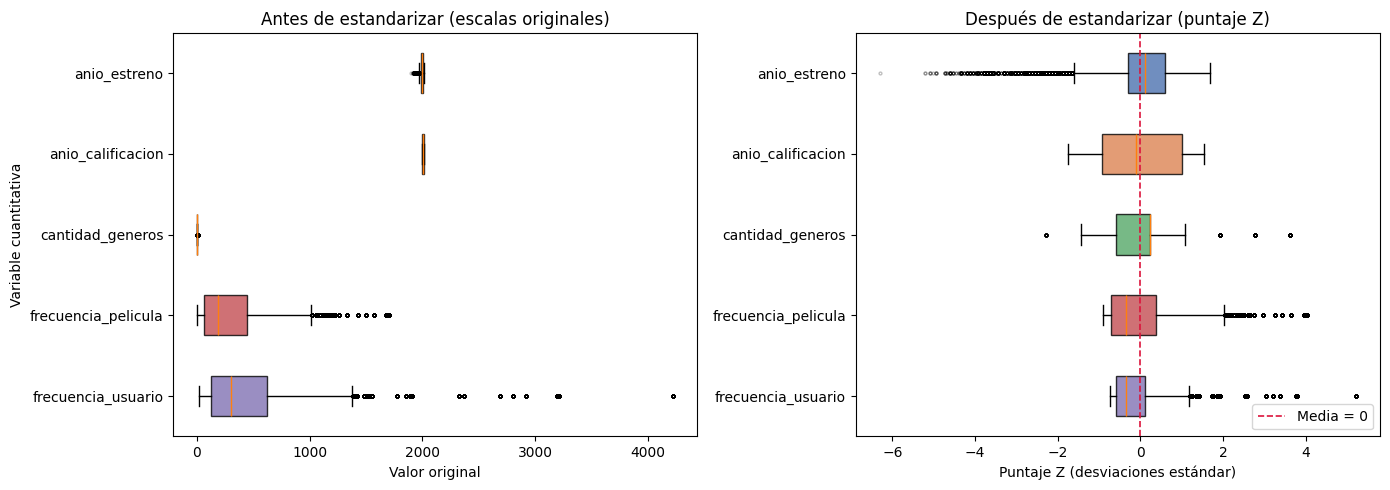

In [12]:
columnas_escalar = [
    "anio_estreno",
    "anio_calificacion",
    "cantidad_generos",
    "frecuencia_pelicula",
    "frecuencia_usuario"
]

df_procesado = df_integrado.copy()
escalador = StandardScaler()
df_procesado[columnas_escalar] = escalador.fit_transform(df_procesado[columnas_escalar])

# Tabla comparativa de estadísticos antes y después de estandarizar
resumen_escalado = pd.DataFrame({
    "media_antes": df_integrado[columnas_escalar].mean(),
    "std_antes": df_integrado[columnas_escalar].std(),
    "min_antes": df_integrado[columnas_escalar].min(),
    "max_antes": df_integrado[columnas_escalar].max(),
    "media_despues": df_procesado[columnas_escalar].mean(),
    "std_despues": df_procesado[columnas_escalar].std(),
    "min_despues": df_procesado[columnas_escalar].min(),
    "max_despues": df_procesado[columnas_escalar].max()
}).round(4)

print("--- Comparación de estadísticos antes y después de StandardScaler ---")
display(resumen_escalado)

# Comparación gráfica antes vs. después sobre muestra aleatoria reproducible
rng = np.random.default_rng(42)
idx_muestra = rng.choice(len(df_integrado), size=min(20000, len(df_integrado)), replace=False)

colores_vars = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]
posiciones = np.arange(1, len(columnas_escalar) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bp_antes = axes[0].boxplot(
    [df_integrado.iloc[idx_muestra][col].to_numpy() for col in columnas_escalar],
    positions=posiciones,
    vert=False,
    patch_artist=True,
    flierprops={"marker": "o", "markersize": 2, "alpha": 0.25}
)
for patch, color in zip(bp_antes["boxes"], colores_vars):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

axes[0].set_yticks(posiciones)
axes[0].set_yticklabels(columnas_escalar)
axes[0].invert_yaxis()
axes[0].set_title("Antes de estandarizar (escalas originales)")
axes[0].set_xlabel("Valor original")
axes[0].set_ylabel("Variable cuantitativa")

bp_despues = axes[1].boxplot(
    [df_procesado.iloc[idx_muestra][col].to_numpy() for col in columnas_escalar],
    positions=posiciones,
    vert=False,
    patch_artist=True,
    flierprops={"marker": "o", "markersize": 2, "alpha": 0.25}
)
for patch, color in zip(bp_despues["boxes"], colores_vars):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

axes[1].axvline(0, color="crimson", linestyle="--", linewidth=1.2, label="Media = 0")
axes[1].set_yticks(posiciones)
axes[1].set_yticklabels(columnas_escalar)
axes[1].invert_yaxis()
axes[1].set_title("Después de estandarizar (puntaje Z)")
axes[1].set_xlabel("Puntaje Z (desviaciones estándar)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

### **Correlación de las variables con evidencia gráfica**

* **Variables evaluadas:** Se calcula la matriz de correlación lineal de Pearson ($r$) sobre las **26 variables numéricas analíticas** de **df_procesado**: **calificacion**, las **5 variables cuantitativas estandarizadas** y las **20 columnas binarias de género**. Se excluyen **id_usuario** e **id_pelicula** por ser claves nominales sin relación de magnitud, así como **titulo** y **fecha_hora** (cuya dimensión temporal ya está representada numéricamente).
* **Gráfico de barras horizontales:** Presenta de forma ordenada el coeficiente de correlación de las **25 variables predictoras** respecto a **calificacion**, diferenciando por color las asociaciones positivas (azul) y negativas (rojo).
* **Mapa de calor (Heatmap):** Muestra las correlaciones cruzadas entre **calificacion**, las variables cuantitativas y los **10 géneros** con mayor magnitud de correlación, permitiendo observar tanto su relación con la calificación como posibles coocurrencias entre variables predictoras.
* **Hallazgos principales:** Las correlaciones lineales individuales con **calificacion** son bajas ($|r| < 0.20$), destacando positivamente **frecuencia_pelicula** (**+0.1933**) y **genero_Drama** (**+0.1235**), y negativamente **frecuencia_usuario** (**-0.1270**), **anio_estreno** (**-0.0865**) y **genero_Comedy** (**-0.0768**). Entre variables predictoras sobresale la coocurrencia entre **genero_Animation** y **genero_Children** (**+0.6552**), así como entre **cantidad_generos** y **genero_Adventure** (**+0.4404**).

In [13]:
columnas_generos = [col for col in df_procesado.columns if col.startswith("genero_")]
columnas_correlacion = ["calificacion"] + columnas_escalar + columnas_generos

matriz_corr = df_procesado[columnas_correlacion].corr(method="pearson")

# Correlación de cada variable respecto a calificacion
corr_con_calificacion = matriz_corr["calificacion"].drop("calificacion")

tabla_corr_calificacion = pd.DataFrame({
    "correlacion_pearson": corr_con_calificacion,
    "magnitud_absoluta": corr_con_calificacion.abs()
}).sort_values(by="magnitud_absoluta", ascending=False).round(4)

print("--- Top 12 variables con mayor correlación respecto a calificacion ---")
display(tabla_corr_calificacion.head(12))

# Pares de variables distintas con mayor correlación entre sí (sin duplicar simetría)
pares_corr = []
cols_matriz = matriz_corr.columns.tolist()
for i in range(len(cols_matriz)):
    for j in range(i + 1, len(cols_matriz)):
        r_val = float(matriz_corr.iloc[i, j])
        pares_corr.append({
            "variable_1": cols_matriz[i],
            "variable_2": cols_matriz[j],
            "correlacion_pearson": r_val,
            "magnitud_absoluta": abs(r_val)
        })

df_pares_corr = (
    pd.DataFrame(pares_corr)
    .sort_values(by="magnitud_absoluta", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

print("\n--- Top 10 pares de variables con mayor correlación entre sí ---")
display(df_pares_corr.head(10))

--- Top 12 variables con mayor correlación respecto a calificacion ---


,correlacion_pearson,magnitud_absoluta
frecuencia_pelicula,0.1933,0.1933
frecuencia_usuario,-0.1270,0.1270
genero_Drama,0.1235,0.1235
anio_estreno,-0.0865,0.0865
genero_Comedy,-0.0768,0.0768
genero_Crime,0.0656,0.0656
genero_Horror,-0.0633,0.0633
genero_War,0.0564,0.0564
genero_Action,-0.0436,0.0436
genero_Mystery,0.0375,0.0375



--- Top 10 pares de variables con mayor correlación entre sí ---


,variable_1,variable_2,correlacion_pearson,magnitud_absoluta
0,genero_Animation,genero_Children,0.6552,0.6552
1,cantidad_generos,genero_Adventure,0.4404,0.4404
2,cantidad_generos,genero_Action,0.4024,0.4024
3,cantidad_generos,genero_Animation,0.3745,0.3745
4,cantidad_generos,genero_Fantasy,0.3402,0.3402
5,cantidad_generos,genero_Children,0.3388,0.3388
6,genero_Action,genero_Adventure,0.3324,0.3324
7,genero_Action,genero_Sci-Fi,0.3270,0.3270
8,genero_Comedy,genero_Thriller,-0.3254,0.3254
9,anio_estreno,anio_calificacion,0.3200,0.3200


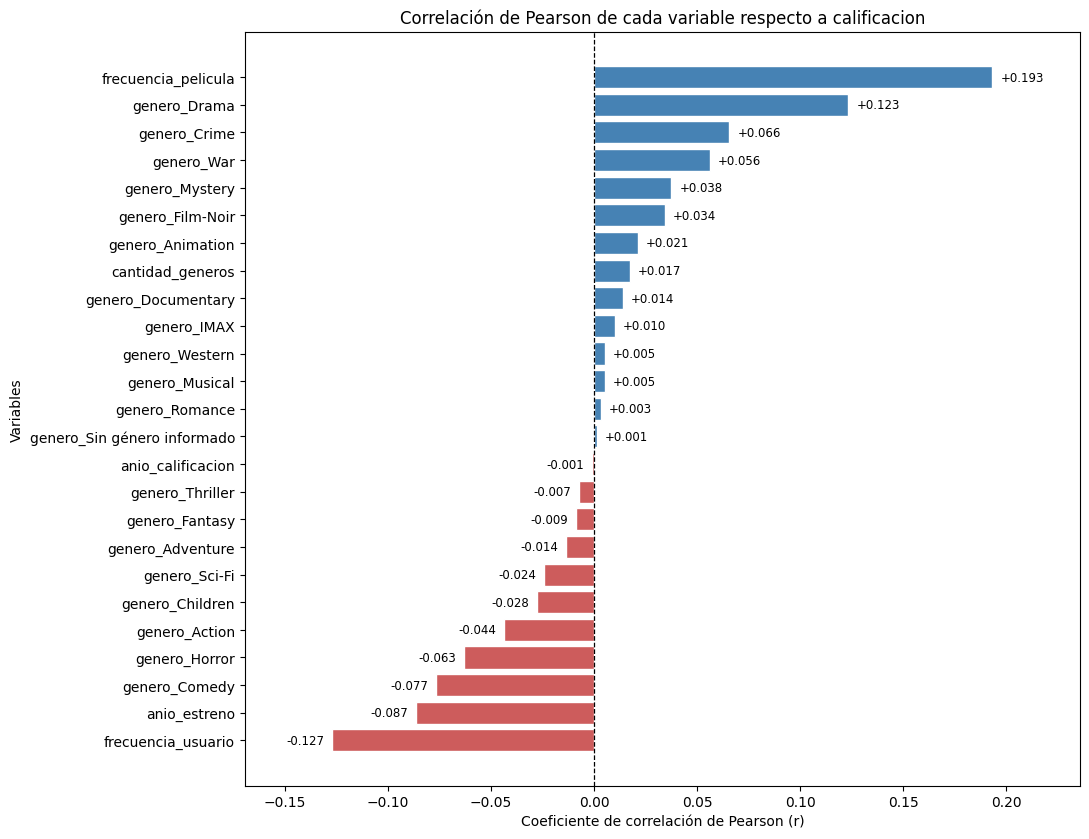

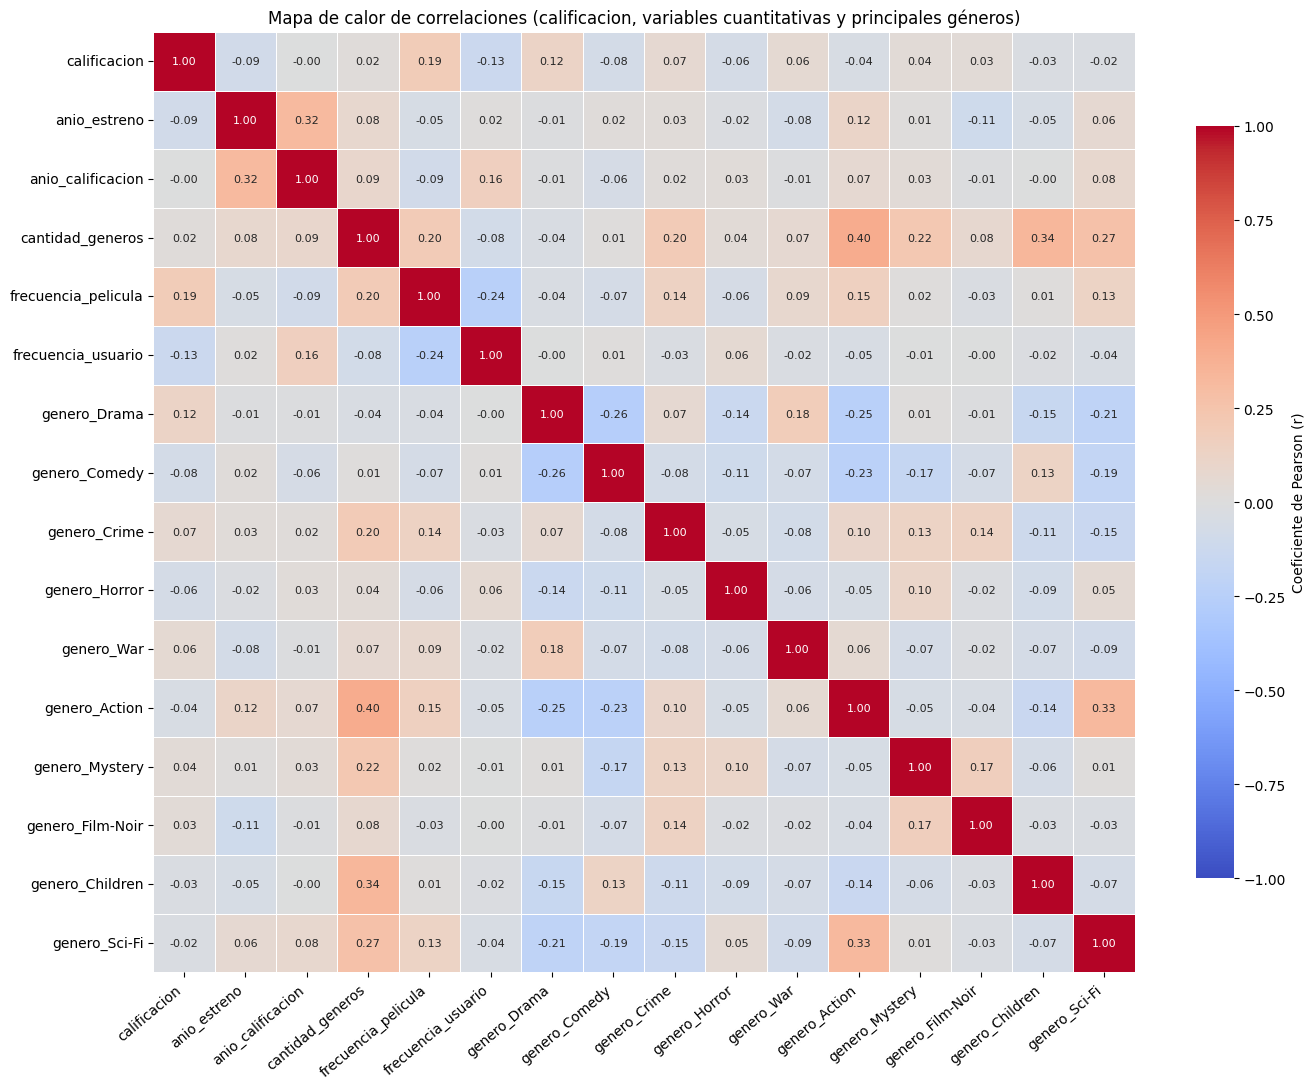

In [14]:
# 1. Gráfico de barras horizontales: correlación de las 25 variables con calificacion
corr_ordenada = corr_con_calificacion.sort_values(ascending=True)
colores_barras = ["indianred" if val < 0 else "steelblue" for val in corr_ordenada.values]

fig, ax = plt.subplots(figsize=(11, 8.5))
ax.barh(corr_ordenada.index, corr_ordenada.values, color=colores_barras, edgecolor="white")
ax.axvline(0, color="black", linestyle="--", linewidth=0.9)

min_r = float(corr_ordenada.min())
max_r = float(corr_ordenada.max())
margen = max(abs(min_r), abs(max_r)) * 0.22
ax.set_xlim(min(min_r - margen, -0.05), max(max_r + margen, 0.05))

offset = max(abs(min_r), abs(max_r)) * 0.02
for idx, val in enumerate(corr_ordenada.values):
    pos_x = val + offset if val >= 0 else val - offset
    alineacion = "left" if val >= 0 else "right"
    ax.text(pos_x, idx, f"{val:+.3f}", va="center", ha=alineacion, fontsize=8.5)

ax.set_title("Correlación de Pearson de cada variable respecto a calificacion")
ax.set_xlabel("Coeficiente de correlación de Pearson (r)")
ax.set_ylabel("Variables")
plt.tight_layout()
plt.show()

# 2. Mapa de calor: calificacion, variables cuantitativas y top 10 géneros más correlacionados
top_generos = (
    corr_con_calificacion[columnas_generos]
    .abs()
    .sort_values(ascending=False)
    .head(10)
    .index
    .tolist()
)
cols_heatmap = ["calificacion"] + columnas_escalar + top_generos

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(
    matriz_corr.loc[cols_heatmap, cols_heatmap],
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    annot_kws={"size": 8},
    cbar_kws={"shrink": 0.8, "label": "Coeficiente de Pearson (r)"},
    ax=ax
)
ax.set_title("Mapa de calor de correlaciones (calificacion, variables cuantitativas y principales géneros)")
plt.xticks(rotation=40, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()